In [96]:
import sqlite3
import pandas as pd


In [97]:
conn = sqlite3.connect('nextgen.db')

In [98]:
conn.execute("""
CREATE TABLE IF NOT EXISTS applicants (
    applicant_id INTEGER PRIMARY KEY,
    name TEXT,
    domain TEXT,
    university TEXT,
    application_date TEXT,
    status TEXT
);
""")

conn.commit()

In [99]:
pd.read_sql("PRAGMA table_info(applicants);", conn)

,cid,name,type,notnull,dflt_value,pk
0,0,applicant_id,INTEGER,0,None,1
1,1,name,TEXT,0,None,0
2,2,domain,TEXT,0,None,0
3,3,university,TEXT,0,None,0
4,4,application_date,TEXT,0,None,0
5,5,status,TEXT,0,None,0


In [100]:
conn.execute("""
CREATE TABLE IF NOT EXISTS interns (
    intern_id INTEGER PRIMARY KEY,
    applicant_id INTEGER,
    start_date TEXT,
    end_date TEXT,
    mentor TEXT,
    completion_status TEXT,
    FOREIGN KEY (applicant_id) REFERENCES applicants(applicant_id)
);
""")

conn.commit()

In [101]:
conn.execute("""
CREATE TABLE IF NOT EXISTS hackathon_scores (
    score_id INTEGER PRIMARY KEY,
    intern_id INTEGER,
    project_name TEXT,
    technical_score REAL,
    presentation_score REAL,
    total_score REAL,
    FOREIGN KEY (intern_id) REFERENCES interns(intern_id)
);
""")

conn.commit()

In [102]:
pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)


,name
0,applicants
1,interns
2,hackathon_scores


In [103]:
applicants_data = [
    (1, 'Ana Silva', 'Data Science', 'University A', '2026-01-10', 'Selected'),
    (2, 'Bruno Costa', 'Web Development', 'University B', '2026-01-12', 'Rejected'),
    (3, 'Carla Mendes', 'Data Science', 'University C', '2026-01-15', 'Selected'),
    (4, 'Daniel Pedro', 'Cybersecurity', 'University A', '2026-01-18', 'Rejected'),
    (5, 'Eva Manuel', 'Web Development', 'University D', '2026-01-20', 'Selected'),
    (6, 'Fernando João', 'Data Science', 'University B', '2026-01-22', 'Selected'),
    (7, 'Grace Santos', 'Cybersecurity', 'University C', '2026-01-25', 'Rejected'),
    (8, 'Helena Costa', 'Data Science', 'University D', '2026-01-28', 'Selected')
]

conn.executemany("""
INSERT OR IGNORE INTO applicants
(applicant_id, name, domain, university, application_date, status)
VALUES (?, ?, ?, ?, ?, ?)
""", applicants_data)

conn.commit()

In [104]:
pd.read_sql("SELECT * FROM applicants;", conn)

,applicant_id,name,domain,university,application_date,status
0,1,Ana Silva,Data Science,University A,2026-01-10,Selected
1,2,Bruno Costa,Web Development,University B,2026-01-12,Rejected
2,3,Carla Mendes,Data Science,University C,2026-01-15,Selected
3,4,Daniel Pedro,Cybersecurity,University A,2026-01-18,Rejected
4,5,Eva Manuel,Web Development,University D,2026-01-20,Selected
5,6,Fernando João,Data Science,University B,2026-01-22,Selected
6,7,Grace Santos,Cybersecurity,University C,2026-01-25,Rejected
7,8,Helena Costa,Data Science,University D,2026-01-28,Selected


In [105]:
interns_data = [
    (1, 1, '2026-02-01', '2026-04-30', 'Mr. James', 'Completed'),
    (2, 3, '2026-02-01', '2026-04-30', 'Ms. Sarah', 'Completed'),
    (3, 5, '2026-02-01', '2026-04-30', 'Mr. David', 'In Progress'),
    (4, 6, '2026-02-01', '2026-04-30', 'Ms. Anna', 'Completed')
]

conn.executemany("""
INSERT OR IGNORE INTO interns
(intern_id, applicant_id, start_date, end_date, mentor, completion_status)
VALUES (?, ?, ?, ?, ?, ?)
""", interns_data)

conn.commit()

In [106]:
pd.read_sql("SELECT * FROM interns;", conn)

,intern_id,applicant_id,start_date,end_date,mentor,completion_status
0,1,1,2026-02-01,2026-04-30,Mr. James,Completed
1,2,3,2026-02-01,2026-04-30,Ms. Sarah,Completed
2,3,5,2026-02-01,2026-04-30,Mr. David,In Progress
3,4,6,2026-02-01,2026-04-30,Ms. Anna,Completed


In [107]:
hackathon_data = [
    (1, 1, 'Smart Health App', 85.0, 90.0, 87.5),
    (2, 2, 'E-learning Platform', 78.0, 82.0, 80.0),
    (3, 3, 'Finance Tracker', 92.0, 88.0, 90.0),
    (4, 4, 'Cybersecurity Tool', 88.0, 95.0, 91.5)
]

conn.executemany("""
INSERT OR IGNORE INTO hackathon_scores
(score_id, intern_id, project_name, technical_score, presentation_score, total_score)
VALUES (?, ?, ?, ?, ?, ?)
""", hackathon_data)

conn.commit()

In [108]:
for table in ['applicants', 'interns', 'hackathon_scores']:
    result = pd.read_sql(
        f"SELECT COUNT(*) AS total FROM {table}", conn
    )
    print(table, ":", result.iloc[0, 0], "registos")

applicants : 8 registos
interns : 4 registos
hackathon_scores : 4 registos


In [109]:
pd.read_sql("SELECT * FROM hackathon_scores;", conn)

,score_id,intern_id,project_name,technical_score,presentation_score,total_score
0,1,1,Smart Health App,85.0,90.0,87.5
1,2,2,E-learning Platform,78.0,82.0,80.0
2,3,3,Finance Tracker,92.0,88.0,90.0
3,4,4,Cybersecurity Tool,88.0,95.0,91.5


In [110]:
query = """
SELECT *
FROM applicants;
"""

pd.read_sql(query, conn)

,applicant_id,name,domain,university,application_date,status
0,1,Ana Silva,Data Science,University A,2026-01-10,Selected
1,2,Bruno Costa,Web Development,University B,2026-01-12,Rejected
2,3,Carla Mendes,Data Science,University C,2026-01-15,Selected
3,4,Daniel Pedro,Cybersecurity,University A,2026-01-18,Rejected
4,5,Eva Manuel,Web Development,University D,2026-01-20,Selected
5,6,Fernando João,Data Science,University B,2026-01-22,Selected
6,7,Grace Santos,Cybersecurity,University C,2026-01-25,Rejected
7,8,Helena Costa,Data Science,University D,2026-01-28,Selected


In [111]:
query = """
SELECT name, domain, status
FROM applicants;
"""

pd.read_sql(query, conn)

,name,domain,status
0,Ana Silva,Data Science,Selected
1,Bruno Costa,Web Development,Rejected
2,Carla Mendes,Data Science,Selected
3,Daniel Pedro,Cybersecurity,Rejected
4,Eva Manuel,Web Development,Selected
5,Fernando João,Data Science,Selected
6,Grace Santos,Cybersecurity,Rejected
7,Helena Costa,Data Science,Selected


In [112]:
query = """
SELECT *
FROM applicants
WHERE status = 'Selected';
"""

pd.read_sql(query, conn)

,applicant_id,name,domain,university,application_date,status
0,1,Ana Silva,Data Science,University A,2026-01-10,Selected
1,3,Carla Mendes,Data Science,University C,2026-01-15,Selected
2,5,Eva Manuel,Web Development,University D,2026-01-20,Selected
3,6,Fernando João,Data Science,University B,2026-01-22,Selected
4,8,Helena Costa,Data Science,University D,2026-01-28,Selected


In [113]:
query = """
SELECT *
FROM applicants
WHERE domain = 'Data Science';
"""

pd.read_sql(query, conn)

,applicant_id,name,domain,university,application_date,status
0,1,Ana Silva,Data Science,University A,2026-01-10,Selected
1,3,Carla Mendes,Data Science,University C,2026-01-15,Selected
2,6,Fernando João,Data Science,University B,2026-01-22,Selected
3,8,Helena Costa,Data Science,University D,2026-01-28,Selected


In [114]:
query = """
SELECT domain, COUNT(*) AS total_applicants
FROM applicants
GROUP BY domain;
"""

pd.read_sql(query, conn)

,domain,total_applicants
0,Cybersecurity,2
1,Data Science,4
2,Web Development,2


In [115]:
query = """
SELECT status, COUNT(*) AS total
FROM applicants
GROUP BY status;
"""

pd.read_sql(query, conn)

,status,total
0,Rejected,3
1,Selected,5


In [116]:
query = """
SELECT AVG(total_score) AS average_score
FROM hackathon_scores;
"""

pd.read_sql(query, conn)

,average_score
0,87.25


In [117]:
query = """
SELECT AVG(technical_score) AS average_technical_score
FROM hackathon_scores;
"""

pd.read_sql(query, conn)

,average_technical_score
0,85.75


In [118]:
query = """
SELECT
    applicants.name,
    applicants.domain,
    interns.mentor,
    interns.completion_status
FROM applicants
INNER JOIN interns
ON applicants.applicant_id = interns.applicant_id;
"""

pd.read_sql(query, conn)

,name,domain,mentor,completion_status
0,Ana Silva,Data Science,Mr. James,Completed
1,Carla Mendes,Data Science,Ms. Sarah,Completed
2,Eva Manuel,Web Development,Mr. David,In Progress
3,Fernando João,Data Science,Ms. Anna,Completed


In [119]:
query = """
SELECT
    applicants.name,
    applicants.domain,
    applicants.status,
    interns.mentor,
    interns.completion_status
FROM applicants
LEFT JOIN interns
ON applicants.applicant_id = interns.applicant_id;
"""

pd.read_sql(query, conn)

,name,domain,status,mentor,completion_status
0,Ana Silva,Data Science,Selected,Mr. James,Completed
1,Bruno Costa,Web Development,Rejected,None,None
2,Carla Mendes,Data Science,Selected,Ms. Sarah,Completed
3,Daniel Pedro,Cybersecurity,Rejected,None,None
4,Eva Manuel,Web Development,Selected,Mr. David,In Progress
5,Fernando João,Data Science,Selected,Ms. Anna,Completed
6,Grace Santos,Cybersecurity,Rejected,None,None
7,Helena Costa,Data Science,Selected,None,None


In [120]:
query = """
SELECT
    applicants.name,
    applicants.domain,
    interns.mentor,
    hackathon_scores.project_name,
    hackathon_scores.technical_score,
    hackathon_scores.presentation_score,
    hackathon_scores.total_score
FROM applicants
INNER JOIN interns
    ON applicants.applicant_id = interns.applicant_id
INNER JOIN hackathon_scores
    ON interns.intern_id = hackathon_scores.intern_id;
"""

pd.read_sql(query, conn)

,name,domain,mentor,project_name,technical_score,presentation_score,total_score
0,Ana Silva,Data Science,Mr. James,Smart Health App,85.0,90.0,87.5
1,Carla Mendes,Data Science,Ms. Sarah,E-learning Platform,78.0,82.0,80.0
2,Eva Manuel,Web Development,Mr. David,Finance Tracker,92.0,88.0,90.0
3,Fernando João,Data Science,Ms. Anna,Cybersecurity Tool,88.0,95.0,91.5


In [121]:
query = """
SELECT
    domain,
    COUNT(*) AS total_applicants,
    SUM(CASE WHEN status = 'Selected' THEN 1 ELSE 0 END) AS selected_applicants,
    ROUND(
        100.0 * SUM(CASE WHEN status = 'Selected' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS selection_rate
FROM applicants
GROUP BY domain;
"""

pd.read_sql(query, conn)

,domain,total_applicants,selected_applicants,selection_rate
0,Cybersecurity,2,0,0.0
1,Data Science,4,4,100.0
2,Web Development,2,1,50.0


In [122]:
query = """
SELECT
    applicants.domain,
    COUNT(interns.intern_id) AS total_interns,
    ROUND(AVG(hackathon_scores.total_score), 2) AS average_score
FROM applicants
INNER JOIN interns
    ON applicants.applicant_id = interns.applicant_id
INNER JOIN hackathon_scores
    ON interns.intern_id = hackathon_scores.intern_id
GROUP BY applicants.domain;
"""

pd.read_sql(query, conn)

,domain,total_interns,average_score
0,Data Science,3,86.33
1,Web Development,1,90.00


In [123]:
query = """
SELECT
    applicants.name,
    applicants.domain,
    hackathon_scores.project_name,
    hackathon_scores.total_score
FROM applicants
INNER JOIN interns
    ON applicants.applicant_id = interns.applicant_id
INNER JOIN hackathon_scores
    ON interns.intern_id = hackathon_scores.intern_id
ORDER BY hackathon_scores.total_score DESC
LIMIT 1;
"""

pd.read_sql(query, conn)

,name,domain,project_name,total_score
0,Fernando João,Data Science,Cybersecurity Tool,91.5


# Part A — SQL Queries

This section presents SQL queries used to analyze internship applications, selection rates, intern performance, and hackathon results.

# Part B — Program Performance Dashboard

This section presents a visual analysis of the internship program using key performance indicators and charts.


In [124]:
total_applicants = pd.read_sql("""
SELECT COUNT(*) AS total
FROM applicants;
""", conn)

print("Total Applicants:", total_applicants.iloc[0, 0])

Total Applicants: 8


In [125]:
total_selected = pd.read_sql("""
SELECT COUNT(*) AS total
FROM applicants
WHERE status = 'Selected';
""", conn)

print("Total Selected:", total_selected.iloc[0, 0])

Total Selected: 5


In [126]:
selection_rate = (
    total_selected.iloc[0, 0] /
    total_applicants.iloc[0, 0]
) * 100

print("Selection Rate:", round(selection_rate, 2), "%")

Selection Rate: 62.5 %


In [127]:
average_score = pd.read_sql("""
SELECT AVG(total_score) AS average
FROM hackathon_scores;
""", conn)

print("Average Hackathon Score:",
      round(average_score.iloc[0, 0], 2))


Average Hackathon Score: 87.25


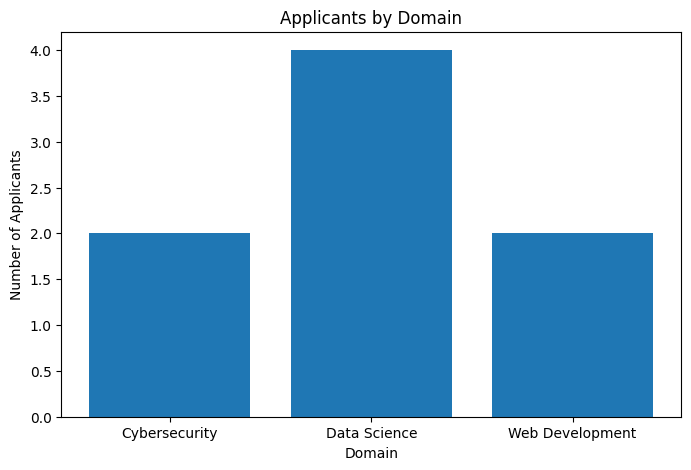

In [128]:
import matplotlib.pyplot as plt

domain_data = pd.read_sql("""
SELECT domain, COUNT(*) AS total
FROM applicants
GROUP BY domain;
""", conn)

plt.figure(figsize=(8, 5))

plt.bar(domain_data['domain'], domain_data['total'])

plt.title('Applicants by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')

plt.show()

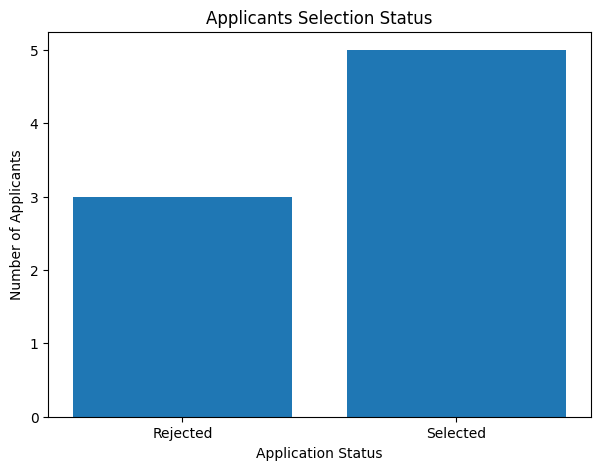

In [129]:
status_data = pd.read_sql("""
SELECT status, COUNT(*) AS total
FROM applicants
GROUP BY status;
""", conn)

plt.figure(figsize=(7, 5))

plt.bar(status_data['status'], status_data['total'])

plt.title('Applicants Selection Status')
plt.xlabel('Application Status')
plt.ylabel('Number of Applicants')

plt.show()

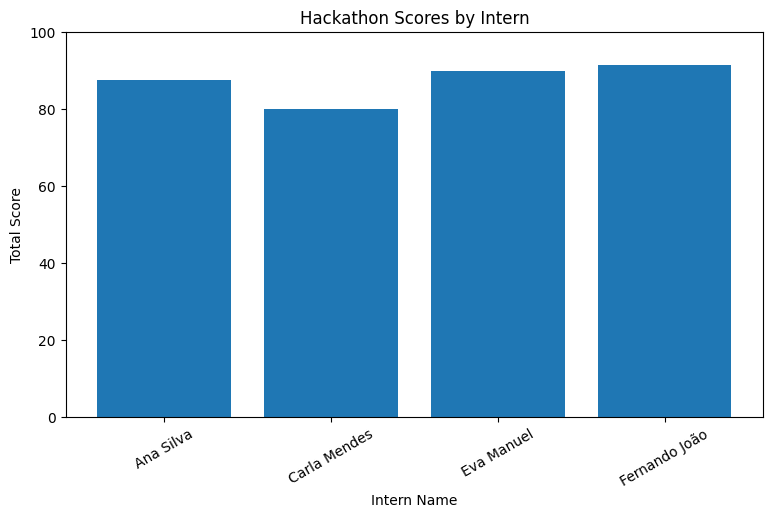

In [130]:
score_data = pd.read_sql("""
SELECT
    applicants.name,
    hackathon_scores.total_score
FROM applicants
INNER JOIN interns
    ON applicants.applicant_id = interns.applicant_id
INNER JOIN hackathon_scores
    ON interns.intern_id = hackathon_scores.intern_id;
""", conn)

plt.figure(figsize=(9, 5))

plt.bar(score_data['name'], score_data['total_score'])

plt.title('Hackathon Scores by Intern')
plt.xlabel('Intern Name')
plt.ylabel('Total Score')

plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

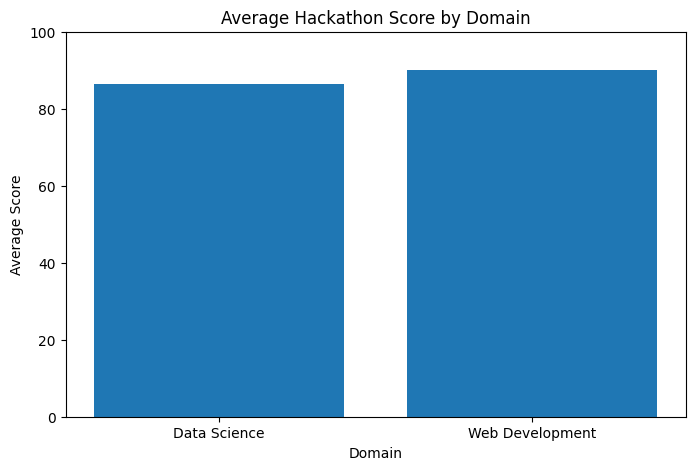

In [131]:
domain_scores = pd.read_sql("""
SELECT
    applicants.domain,
    AVG(hackathon_scores.total_score) AS average_score
FROM applicants
INNER JOIN interns
    ON applicants.applicant_id = interns.applicant_id
INNER JOIN hackathon_scores
    ON interns.intern_id = hackathon_scores.intern_id
GROUP BY applicants.domain;
""", conn)

plt.figure(figsize=(8, 5))

plt.bar(domain_scores['domain'], domain_scores['average_score'])

plt.title('Average Hackathon Score by Domain')
plt.xlabel('Domain')
plt.ylabel('Average Score')

plt.ylim(0, 100)
plt.show()


In [132]:
from google.colab import output
output.enable_custom_widget_manager()

In [133]:
import ipywidgets as widgets
from IPython.display import display

dashboard_data = pd.read_sql("""
SELECT
    applicants.name,
    applicants.domain,
    applicants.status,
    interns.mentor,
    hackathon_scores.total_score
FROM applicants
LEFT JOIN interns
    ON applicants.applicant_id = interns.applicant_id
LEFT JOIN hackathon_scores
    ON interns.intern_id = hackathon_scores.intern_id;
""", conn)

domain_filter = widgets.Dropdown(
    options=['All'] + sorted(dashboard_data['domain'].unique().tolist()),
    value='All',
    description='Domain:'
)

def filter_dashboard(domain):
    if domain == 'All':
        filtered_data = dashboard_data
    else:
        filtered_data = dashboard_data[
            dashboard_data['domain'] == domain
        ]

    print("Total Applicants:", len(filtered_data))
    print("Selected:", (filtered_data['status'] == 'Selected').sum())

    display(filtered_data)

widgets.interact(filter_dashboard, domain=domain_filter);

interactive(children=(Dropdown(description='Domain:', options=('All', 'Cybersecurity', 'Data Science', 'Web De…

In [134]:
def filter_dashboard(domain):

    if domain == 'All':
        filtered_data = dashboard_data.copy()
    else:
        filtered_data = dashboard_data[
            dashboard_data['domain'] == domain
        ].copy()

    # KPIs
    total = len(filtered_data)
    selected = (filtered_data['status'] == 'Selected').sum()

    print("Total Applicants:", total)
    print("Selected Applicants:", selected)

    # Applicants by Status
    status_counts = filtered_data['status'].value_counts()

    plt.figure(figsize=(6, 4))
    plt.bar(status_counts.index, status_counts.values)
    plt.title('Applicants by Status')
    plt.xlabel('Status')
    plt.ylabel('Number of Applicants')
    plt.show()

    # Hackathon Scores
    scores = filtered_data.dropna(subset=['total_score'])

    plt.figure(figsize=(8, 4))
    plt.bar(scores['name'], scores['total_score'])
    plt.title('Hackathon Scores')
    plt.xlabel('Intern')
    plt.ylabel('Total Score')
    plt.ylim(0, 100)
    plt.xticks(rotation=30)
    plt.show()

    display(filtered_data)

widgets.interact(filter_dashboard, domain=domain_filter);

interactive(children=(Dropdown(description='Domain:', options=('All', 'Cybersecurity', 'Data Science', 'Web De…

# Internship Program Performance Dashboard

## Project Overview

This dashboard analyzes the performance of an internship program using SQL, Python, Pandas, Matplotlib and SQLite.

The project provides insights into:

- Total number of applicants.
- Number of selected applicants.
- Applicant distribution by domain.
- Internship selection status.
- Hackathon performance and average scores.

## Interactive Analysis

Users can select different domains to explore applicant information and compare performance indicators.

## Database Structure

The project uses three relational tables:

1. **Applicants:** Stores applicant information and application status.
2. **Interns:** Stores internship details and mentor information.
3. **Hackathon Scores:** Stores technical, presentation and total scores.

## Conclusion

This project demonstrates how SQL and Python can be used to manage, analyze and visualize internship program data.

The dashboard provides useful insights into applicant distribution, selection rates and hackathon performance.

The interactive domain filter allows users to explore the data more efficiently and compare different areas of the internship program.

The project helped develop practical skills in SQL, database management, data analysis and data visualization.